In [1]:
# path setup (scripts/nb_layout.py): run from the folder this notebook belongs to, with scripts/ importable
import os, sys
if '_HHS_ROOT' not in globals():
    _d = os.getcwd()
    while os.path.basename(_d) != 'notebooks' and os.path.dirname(_d) != _d:
        _d = os.path.dirname(_d)
    _HHS_ROOT = os.path.dirname(_d) if os.path.basename(_d) == 'notebooks' else os.getcwd()
    os.chdir(os.path.join(_HHS_ROOT, '.'))
    sys.path[:0] = [os.path.join(_HHS_ROOT, 'scripts'), os.getcwd()]

# PRR against the pool CBR (campaign v3)

**Schemes.** Leader HARQ Option 2 (**R3**), the blind helper with soft combining (**R4+C**, `R4_bsc`: Kuo's helper
relays in every handed-over slot, receivers combine the blind copies) and the cooperative protocol (**R6**).
**R4 + C + fallback** (`R4_bsc_fb`) is drawn too once `out/remote_v3_fb` exists (campaign `v3_fb`).

**Data.** `out/remote_v3`: 3 routes × 2 traffic types × 0 / 15 / 30 / 45 / 60 background vehicles × 10 seeds per
scheme. Points: mean over seeds; bars: 95 % Student-t half-width on both axes.

**Pool CBR** = `cbr_occupied` of the run: the share of the pool's (slot, subchannel) cells used by any vehicle in the
KPI window, each cell counted once. The run's `cbr` column is the *offered* load (every transmitted
subchannel-slot, overlapping transmissions counted more than once); it reaches 0.98–1.07 at 60 vehicles and is not a
CBR. The platoon's own share is under 1 % of the pool, so the CBR is the same for every scheme at a given load. This
is a global occupancy count, not the 3GPP CBR measured by one UE (S-RSSI above a threshold over 100 ms).

**Δ** panels: change against the scheme's own value at 0 vehicles. The 0-vehicle and loaded runs use different
SUMO traces, so the interval of a Δ combines both intervals (unpaired).

In [2]:
import pandas as pd
import plot_prr_vs_cbr as P
D = P.load()
M = P.means(D)
print(len(D), 'runs;', 'arms:', ', '.join(P.ARMS[a][0] for a in M.arm.unique()))
print('seeds per point:', sorted(D.groupby(['arm', 'sc', 'tr', 'nbg']).size().unique()))
cbr = M.groupby('nbg').cbr.agg(['mean', 'min', 'max']).mul(100).round(1)
cbr.join(M.groupby('nbg').cbr_offered.mean().mul(100).round(1).rename('offered load (%)')) \
   .rename(columns=lambda c: c if 'offered' in c else f'pool CBR {c} (%)')

900 runs; arms: Leader Opt. 2 (R3), Blind helper + C (R4+C), Cooperative (R6)
seeds per point: [np.int64(10)]


,pool CBR mean (%),pool CBR min (%),pool CBR max (%),offered load (%)
nbg,,,,
0,0.7,0.3,0.9,0.7
15,23.3,22.7,24.3,24.7
30,42.3,42.0,42.6,48.9
45,58.0,57.5,58.9,74.1
60,69.4,68.9,70.2,98.5


## 1. Group PRR (mean member PRR)

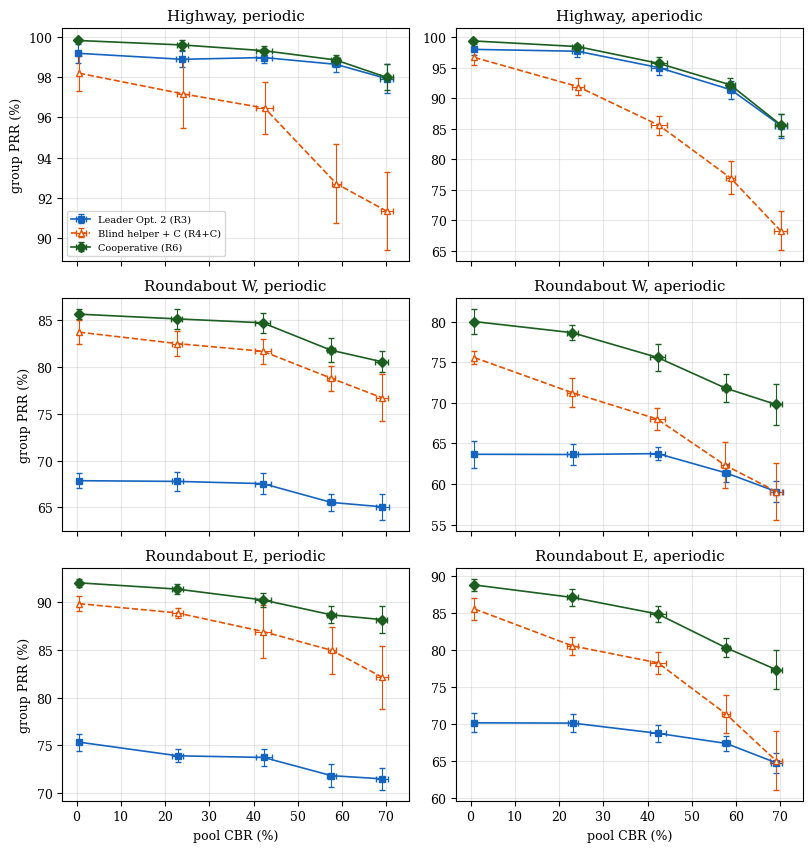

In [3]:
P.grid(M, 'prr', 'group PRR (%)', 'prr_vs_cbr');

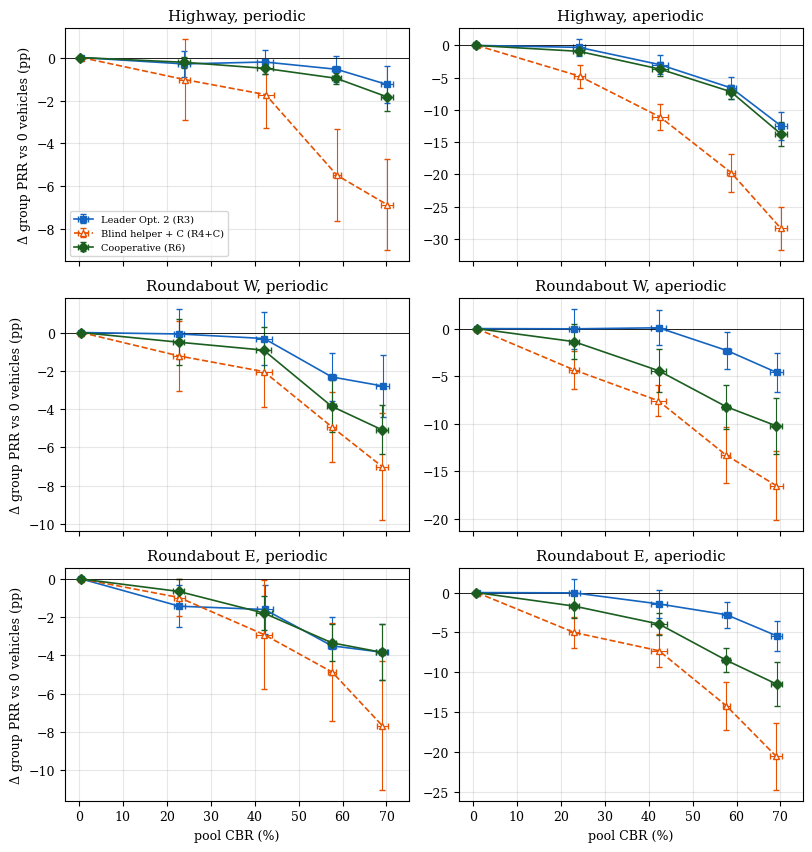

In [4]:
P.grid(M, 'dprr', 'Δ group PRR vs 0 vehicles (pp)', 'dprr_vs_cbr', hline=0);

## 2. Worst receiver (worst member PRR)

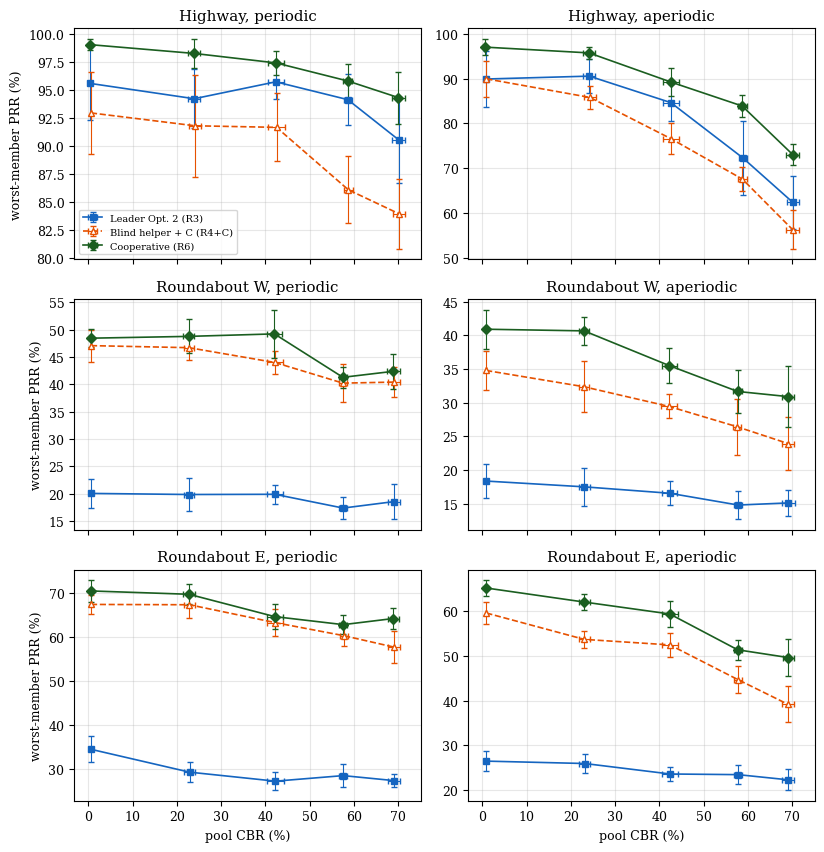

In [5]:
P.grid(M, 'worst', 'worst-member PRR (%)', 'worst_vs_cbr');

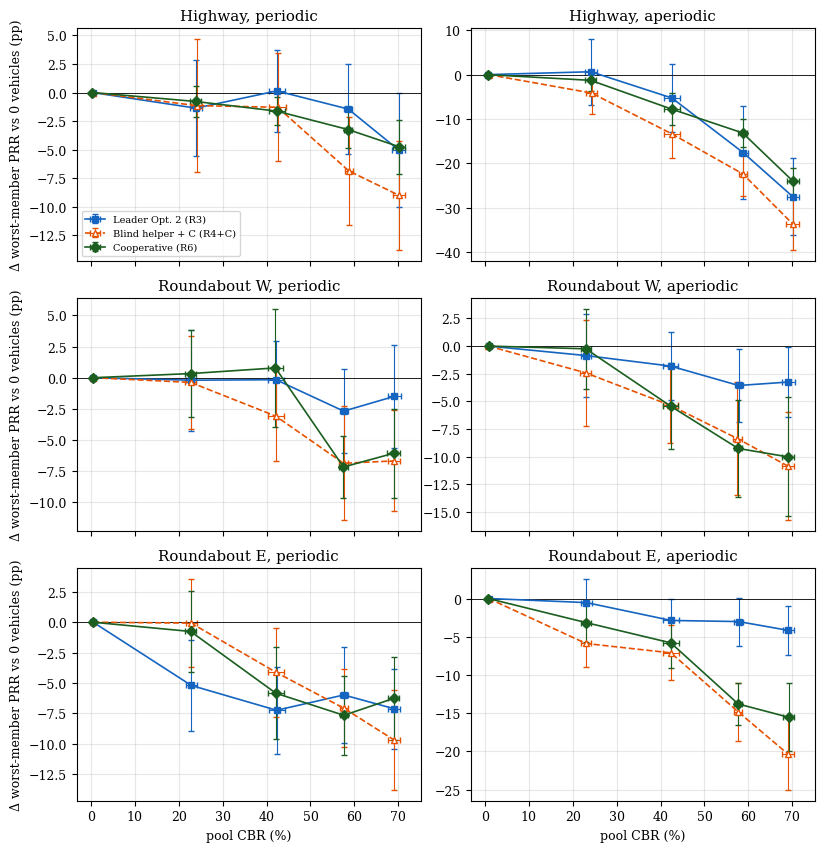

In [6]:
P.grid(M, 'dworst', 'Δ worst-member PRR vs 0 vehicles (pp)', 'dworst_vs_cbr', hline=0);

## 3. Tables

Mean group and worst-member PRR (%) per route, traffic and load, and the drop from 0 to 60 vehicles (pp).

In [7]:
lab = {a: P.ARMS[a][0] for a in P.ARMS}
T = M.assign(scheme=M.arm.map(lab), route=M.sc.map(P.SCN), traffic=M.tr.map(P.TRN), CBR=(100 * M.cbr).round(0))
with pd.option_context('display.max_rows', 100):
    display(T.pivot_table(index=['route', 'traffic', 'nbg'], columns='scheme', values=['prr', 'worst']).round(1))
    display(T[T.nbg == 60].pivot_table(index=['route', 'traffic'], columns='scheme',
                                       values=['dprr', 'dworst']).round(1))
M.round(4).to_csv(f'{P.FIG}/prr_vs_cbr.csv', index=False)

prr                   \
scheme                     Blind helper + C (R4+C) Cooperative (R6)   
route        traffic   nbg                                            
Highway      aperiodic 0                      96.7             99.4   
                       15                     91.9             98.4   
                       30                     85.5             95.7   
                       45                     76.9             92.2   
                       60                     68.3             85.6   
             periodic  0                      98.2             99.8   
                       15                     97.2             99.6   
                       30                     96.5             99.3   
                       45                     92.7             98.8   
                       60                     91.3             98.0   
Roundabout E aperiodic 0                      85.6             88.9   
                       15                     80.6             87.2   
                       30                     78.3             84.9   
                       45                     71.4             80.4   
                       60                     65.1             77.4   
             periodic  0                      89.8             92.0   
                       15                     88.9             91.4   
                       30                     86.9             90.2   
                       45                     84.9             88.7   
                       60                     82.1             88.2   
Roundabout W aperiodic 0                      75.6             80.0   
                       15                     71.3             78.7   
                       30                     68.0             75.6   
                       45                     62.3             71.8   
                       60                     59.1             69.8   
             periodic  0                      83.7             85.7   
                       15                     82.5             85.2   
                       30                     81.7             84.7   
                       45                     78.8             81.8   
                       60                     76.7             80.6   

                                                                worst  \
scheme                     Leader Opt. 2 (R3) Blind helper + C (R4+C)   
route        traffic   nbg                                              
Highway      aperiodic 0                 98.0                    90.0   
                       15                97.7                    85.8   
                       30                95.0                    76.6   
                       45                91.4                    67.6   
                       60                85.5                    56.4   
             periodic  0                 99.2                    92.9   
                       15                98.9                    91.8   
                       30                99.0                    91.6   
                       45                98.6                    86.1   
                       60                97.9                    83.9   
Roundabout E aperiodic 0                 70.2                    59.5   
                       15                70.2                    53.6   
                       30                68.8                    52.4   
                       45                67.4                    44.7   
                       60                64.8                    39.2   
             periodic  0                 75.4                    67.4   
                       15                73.9                    67.3   
                       30                73.8                    63.2   
                       45                71.8                    60.3   
                       60                71.5                    57.7   
Roundabout W aperiodic 0

dprr                   \
scheme                 Blind helper + C (R4+C) Cooperative (R6)   
route        traffic                                              
Highway      aperiodic                   -28.4            -13.8   
             periodic                     -6.8             -1.8   
Roundabout E aperiodic                   -20.5            -11.5   
             periodic                     -7.7             -3.8   
Roundabout W aperiodic                   -16.5            -10.2   
             periodic                     -7.0             -5.1   

                                                           dworst  \
scheme                 Leader Opt. 2 (R3) Blind helper + C (R4+C)   
route        traffic                                                
Highway      aperiodic              -12.5                   -33.6   
             periodic                -1.3                    -9.0   
Roundabout E aperiodic               -5.4                   -20.4   
             periodic                -3.8                    -9.7   
Roundabout W aperiodic               -4.6                   -10.9   
             periodic                -2.8                    -6.7   

                                                            
scheme                 Cooperative (R6) Leader Opt. 2 (R3)  
route        traffic                                        
Highway      aperiodic            -24.0              -27.5  
             periodic              -4.7               -5.0  
Roundabout E aperiodic            -15.5               -4.2  
             periodic              -6.3               -7.1  
Roundabout W aperiodic            -10.0               -3.2  
             periodic              -6.1               -1.5

## 4. Findings (R3, R4+C, R6; pool CBR 0 → 0.70)

**The load axis.** 0 / 15 / 30 / 45 / 60 vehicles give a pool CBR of 0.01 / 0.23–0.24 / 0.42–0.43 / 0.58–0.59 /
0.69–0.70 (offered load 0.01 / 0.25 / 0.49 / 0.74 / 0.99). Earlier notes quoting "CBR 0.99" at 60 vehicles used the
offered load.

**Group PRR.**
- R4+C is the most load-sensitive scheme: its blind copies add collisions. Aperiodic traffic, 0 → 60 vehicles:
  −28 pp on the highway (96.7 → 68.3 %), −16 to −21 pp on the roundabouts; at CBR 0.70 it falls to R3's level on both
  roundabouts (59.1 vs 59.1 % W, 65.1 vs 64.8 % E), having lost its blockage advantage.
- R3 is the least sensitive on the roundabouts (−3 to −5 pp) but starts low there (64–75 %): it cannot get around the
  buildings.
- R6 tracks R3 on the highway (aperiodic 85.6 vs 85.5 % at CBR 0.70) and loses more than R3 on the roundabouts with
  aperiodic traffic (−10 to −11 pp against −5) but stays on top at every CBR (10–13 pp above both at 0.70).
- Periodic traffic suffers far less for every scheme (reservations are announced, so the background avoids them).

**Worst receiver.**
- R6 has the highest mean worst member in every route, traffic and load (not always significantly against R4+C
  with periodic traffic on the roundabouts; e.g. 30.9 / 49.6 % at 60 vehicles, aperiodic, W / E,
  against 23.9 / 39.2 % for R4+C and 15.1 / 22.3 % for R3).
- The load costs the worst member more than the group: on the highway, aperiodic, 0 → 60 vehicles R3 −27.5, R4+C
  −33.6, R6 −24.0 pp. On the roundabouts R4+C and R6 lose 6–20 pp, R3 only 2–7 pp, from a much lower start
  (18–34 %): its worst member is limited by blockage, not by the load.
- R4+C keeps most of R6's worst-member level with periodic traffic (40.4 vs 42.4 % at 60 vehicles, W) but not with
  aperiodic traffic (23.9 vs 30.9 %, E: 39.2 vs 49.6 %).

In [8]:
if 'R4_bsc_fb' in M.arm.values:
    print('R4 + C + fallback is included above; see the fallback notebook for the paired takeover gain.')
else:
    print('R4 + C + fallback: not yet copied (out/remote_v3_fb). Rebuild after copying to include it.')

R4 + C + fallback: not yet copied (out/remote_v3_fb). Rebuild after copying to include it.
